In [1]:
 from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
!pip install scikit-learn seaborn -q

In [3]:
FEATURE_PATH = "/content/drive/MyDrive/RetinalStrokeProject/features.csv"

df = pd.read_csv(FEATURE_PATH)

print(df.shape)

df.head()

(14, 6)


,image_name,vessel_density,vessel_length,branch_points,end_points,tortuosity
0,09_dr.JPG,0.030357,2895,49,405,4.740268
1,09_g.png,0.059147,5015,150,302,9.914359
2,13_h.png,0.072987,5867,177,461,11.049043
3,14_h.png,0.069824,5628,188,355,11.064258
4,14_test.png,0.069733,4721,243,240,10.436724


In [4]:
feature_cols = [
    "vessel_density",
    "vessel_length",
    "branch_points",
    "end_points",
    "tortuosity"
]

scaler = MinMaxScaler()

df_scaled = df.copy()

df_scaled[feature_cols] = scaler.fit_transform(
    df[feature_cols]
)

df_scaled.head()

,image_name,vessel_density,vessel_length,branch_points,end_points,tortuosity
0,09_dr.JPG,0.000000,0.000000,0.000000,0.801418,0.000000
1,09_g.png,0.674381,0.713324,0.448889,0.436170,0.734065
2,13_h.png,0.998570,1.000000,0.568889,1.000000,0.895047
3,14_h.png,0.924493,0.919583,0.617778,0.624113,0.897205
4,14_test.png,0.922348,0.614401,0.862222,0.216312,0.808175


In [5]:
df_scaled["stroke_risk_score"] = (
      0.30 * df_scaled["vessel_density"]
    + 0.20 * df_scaled["vessel_length"]
    + 0.20 * df_scaled["branch_points"]
    + 0.10 * df_scaled["end_points"]
    + 0.20 * df_scaled["tortuosity"]
)

df_scaled.head()

,image_name,vessel_density,vessel_length,branch_points,end_points,tortuosity,stroke_risk_score
0,09_dr.JPG,0.000000,0.000000,0.000000,0.801418,0.000000,0.080142
1,09_g.png,0.674381,0.713324,0.448889,0.436170,0.734065,0.625187
2,13_h.png,0.998570,1.000000,0.568889,1.000000,0.895047,0.892358
3,14_h.png,0.924493,0.919583,0.617778,0.624113,0.897205,0.826672
4,14_test.png,0.922348,0.614401,0.862222,0.216312,0.808175,0.755295


In [6]:
def classify_risk(score):

    if score < 0.33:
        return "Low"

    elif score < 0.66:
        return "Medium"

    else:
        return "High"


df_scaled["risk_category"] = (
    df_scaled["stroke_risk_score"]
    .apply(classify_risk)
)

df_scaled.head()

,image_name,vessel_density,vessel_length,branch_points,end_points,tortuosity,stroke_risk_score,risk_category
0,09_dr.JPG,0.000000,0.000000,0.000000,0.801418,0.000000,0.080142,Low
1,09_g.png,0.674381,0.713324,0.448889,0.436170,0.734065,0.625187,Medium
2,13_h.png,0.998570,1.000000,0.568889,1.000000,0.895047,0.892358,High
3,14_h.png,0.924493,0.919583,0.617778,0.624113,0.897205,0.826672,High
4,14_test.png,0.922348,0.614401,0.862222,0.216312,0.808175,0.755295,High


In [7]:
print(
    df_scaled[
        [
            "image_name",
            "stroke_risk_score",
            "risk_category"
        ]
    ]
)

         image_name  stroke_risk_score risk_category
0         09_dr.JPG           0.080142           Low
1          09_g.png           0.625187        Medium
2          13_h.png           0.892358          High
3          14_h.png           0.826672          High
4       14_test.png           0.755295          High
5          15_g.png           0.810795          High
6       15_test.png           0.944349          High
7       18_test.png           0.640341        Medium
8   21_training.png           0.466653        Medium
9   25_training.png           0.503419        Medium
10  29_training.png           0.724506          High
11  32_training.png           0.470659        Medium
12  33_training.png           0.614881        Medium
13  39_training.png           0.602745        Medium


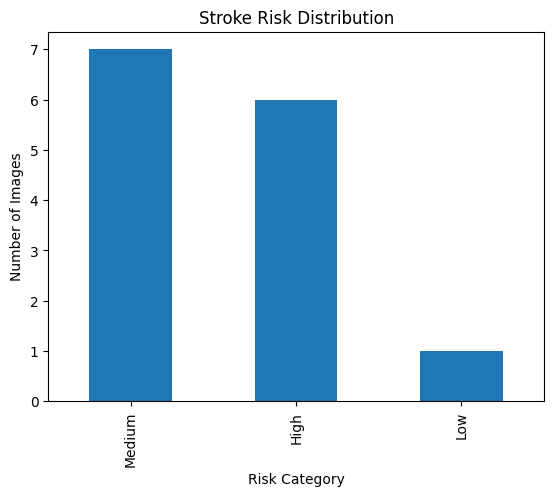

In [8]:
import matplotlib.pyplot as plt

df_scaled["risk_category"].value_counts().plot(
    kind="bar"
)

plt.title("Stroke Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Images")

plt.show()

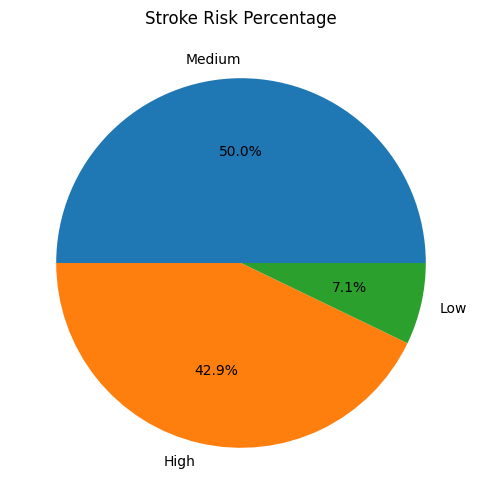

In [9]:
plt.figure(figsize=(6,6))

df_scaled["risk_category"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")
plt.title("Stroke Risk Percentage")

plt.show()

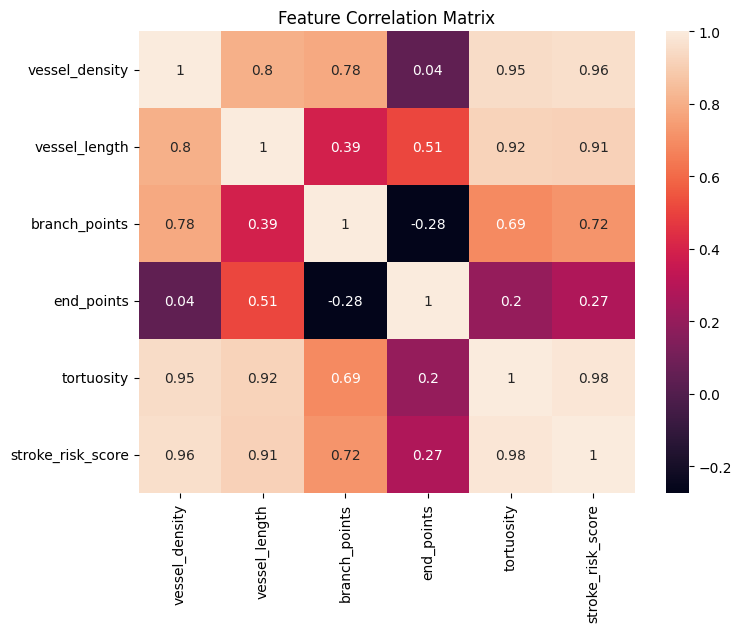

In [10]:
import seaborn as sns

plt.figure(figsize=(8,6))

sns.heatmap(
    df_scaled[
        [
            "vessel_density",
            "vessel_length",
            "branch_points",
            "end_points",
            "tortuosity",
            "stroke_risk_score"
        ]
    ].corr(),
    annot=True
)

plt.title("Feature Correlation Matrix")

plt.show()

In [11]:
RESULT_PATH = "/content/drive/MyDrive/RetinalStrokeProject/stroke_risk_results.csv"

df_scaled.to_csv(
    RESULT_PATH,
    index=False
)

print("Saved:", RESULT_PATH)

Saved: /content/drive/MyDrive/RetinalStrokeProject/stroke_risk_results.csv
